# 04 · One Dataset, Different Layouts

**NHyDB 0.27.1 notebook series · v1**

A layout is only a **way of looking** at the address space: it decides which cells a record uses. The cell identity stays `(R, u, v, lane)` with its number `N`. We store the same six planets with three different layouts and compare the cell patterns, then let several layouts share one realm, change a layout safely – and write a layout of our own.

> **Who is this for?** This notebook starts with a short introduction and continues with runnable examples. **New to NHyDB?** Read from top to bottom – every idea is introduced before it is used. **Already know the basics?** Skip the sections marked 📘 *Background* and jump to the experiments marked ▶. All cells run from top to bottom; optional deep dives are marked ⏩ *Advanced*.

**What you will learn**

* the three built-in geometries **CLASSIC**, **COLUMN** and **PACKED**
* that the same records produce **different cell patterns** – and still read back identically
* **routing**: which layout owns a `u` when several share a realm (priority, narrower range, id)
* **layout evolution**: a dry run first, and why changes that would re-route stored data are rejected
* ⏩ a **CUSTOM** layout written in Python that puts each record into one Dynadron group

**Recommended before:** [02 · From Mathematics to Stored Values](02_from_address_to_data_v1.ipynb) and [03 · Records, Fields and Lanes](03_records_fields_and_lanes_v1.ipynb).

### Setup

The next cell checks the environment and defines a few small plotting helpers used in
this notebook. It is collapsed because it is not about NHyDB itself – feel free to open
it. Every database in this notebook lives in a temporary folder that is removed at
the end.

In [1]:
import math
import os
import shutil
import sys
import tempfile

import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

import nhydb

# --- environment check ---------------------------------------------------------
EXPECTED = "0.27.1"
print(f"Python {sys.version.split()[0]} · nhydb {nhydb.ENGINE_VERSION} · "
      f"file format {nhydb.FILE_FORMAT_VERSION} · matplotlib {matplotlib.__version__}")
if nhydb.ENGINE_VERSION != EXPECTED:
    print(f"⚠ This notebook was written for NHyDB {EXPECTED}; results may differ.")

# --- a private temporary folder for all databases of this notebook --------------
WORKDIR = tempfile.mkdtemp(prefix="nhydb_notebook_")


def db_path(name):
    """Path of a new database file inside the temporary folder."""
    return os.path.join(WORKDIR, name)


def cleanup():
    shutil.rmtree(WORKDIR, ignore_errors=True)


def file_sizes(path):
    """Sizes of the files that belong to a database (bytes)."""
    folder, base = os.path.split(path)
    return {f: os.path.getsize(os.path.join(folder, f))
            for f in sorted(os.listdir(folder)) if f.startswith(base)}


# --- one visual language for the whole series -----------------------------------
# Layer A (mathematical address space) = blue tones, layer B (logical data model) =
# green, layer C (storage engine) = slate grey. Lanes and boundary points belong to A.
COLORS = {
    "A": "#1d4ed8", "A_light": "#dbeafe",
    "B": "#15803d", "B_light": "#dcfce7",
    "C": "#475569", "C_light": "#e2e8f0",
    "NL": "#2563eb", "NR": "#7c3aed",
    "GZ": "#dc2626", "N0": "#9ca3af",
    "attention": "#ea580c", "ok": "#16a34a", "bad": "#dc2626",
}
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})


def kind_of(n):
    """'NL', 'NR', 'GZ' or 'N0' for a natural number n >= 1 (computed by NHyDB)."""
    try:
        return nhydb.n_to_dynadron_address(n)["lane_name"]
    except nhydb.AddressError:
        return "GZ" if math.isqrt(n) ** 2 == n else "N0"


def group_of(n):
    """The group G whose interval [G(G-1), G(G+1)) contains n."""
    g = math.isqrt(n)
    return g + 1 if n - g * g >= g else g       # N0(g+1) and the NL cells of g+1 lie above g² + g − 1


KIND_LABEL = {"NL": "NL cell", "NR": "NR cell", "GZ": "GZ point (G²)", "N0": "N0 point (G·(G−1))"}


def plot_path(ax, steps, title=None):
    """'From input to value': boxes coloured by layer A/B/C, connected by arrows.

    ``steps`` is a list of (layer, heading, text) with layer in {"A", "B", "C"}.
    """
    n = len(steps)
    width, gap = 1.0, 0.35
    for i, (layer, head, text) in enumerate(steps):
        x = i * (width + gap)
        ax.add_patch(FancyBboxPatch((x, 0), width, 1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                    facecolor=COLORS[layer + "_light"], edgecolor=COLORS[layer], lw=1.6))
        ax.text(x + width / 2, 0.80, head, ha="center", va="center", fontsize=8.5,
                fontweight="bold", color=COLORS[layer])
        ax.text(x + width / 2, 0.40, text, ha="center", va="center", fontsize=8, color="#111827",
                wrap=True)
        if i < n - 1:
            ax.annotate("", xy=(x + width + gap - 0.02, 0.5), xytext=(x + width + 0.02, 0.5),
                        arrowprops=dict(arrowstyle="-|>", color="#334155", lw=1.3))
    ax.set_xlim(-0.1, n * (width + gap) - gap + 0.1)
    ax.set_ylim(-0.35, 1.15)
    ax.axis("off")
    for j, (layer, name) in enumerate([("A", "A · address space"), ("B", "B · data model"),
                                       ("C", "C · storage engine")]):
        ax.text(j * 1.6, -0.25, "■ " + name, color=COLORS[layer], fontsize=8.5, fontweight="bold")
    if title:
        ax.set_title(title)

import pandas as pd

PLANET_COLORS = ["#0f766e", "#b45309", "#1d4ed8", "#be123c", "#6d28d9", "#4d7c0f"]


def plot_layout_cells(ax, cells, u_max, v_max, title):
    """Cells (u, v) of one layout, coloured by record; labels: record short name + field."""
    for c in cells:
        color = PLANET_COLORS[(c["object"] - 1) % len(PLANET_COLORS)]
        ax.add_patch(Rectangle((c["u"] - 0.47, c["v"] - 0.45), 0.94, 0.9, facecolor=color, alpha=0.9,
                               edgecolor="white"))
        ax.text(c["u"], c["v"], f"{c['short']} {c['field']}", ha="center", va="center", fontsize=7,
                color="white", fontweight="bold")
    ax.set_xlim(0.5, u_max + 0.5)
    ax.set_ylim(0.5, v_max + 0.5)
    ax.set_xticks(range(1, u_max + 1))
    ax.set_yticks(range(1, v_max + 1, 1 if v_max <= 12 else 2))
    ax.set_xlabel("u")
    ax.set_ylabel("v")
    ax.grid(color="#e2e8f0", lw=0.5)
    ax.set_axisbelow(True)
    ax.set_title(title, fontsize=10)

Python 3.14.5 · nhydb 0.27.1 · file format 0.16 · matplotlib 3.11.2


## 📘 Background: what a layout decides

| Layout | record (object) | field | anchor (the record's own cell) |
|---|---|---|---|
| **CLASSIC** | `u` | `v` (shape field) | `v = 1` |
| **COLUMN** | `v` | one fixed `u` per field | `u` of the first field |
| **PACKED** | block number along `v` of one `u` | offset inside a block of `span` cells | offset 0 |
| **CUSTOM** | your Python plugin | your plugin | your plugin |

The layout is part of the **schema** (layer B). It never changes what a cell *is* – it only decides
which cells an object uses. Writing and reading objects works the same for every layout:
`put_object` / `put_objects_batch` / `get_object`.

## 1 · Six planets, three layouts

**Question:** What happens to the cells if we only change the layout?

▶ **Run it:** three databases, each with realm 1 and one layout – CLASSIC, COLUMN, PACKED (span 4).
The data is exactly the same.

In [2]:
PLANETS = {
    1: {"name": "Mercury", "mass": 0.330, "moons": 0},
    2: {"name": "Venus",   "mass": 4.87,  "moons": 0},
    3: {"name": "Earth",   "mass": 5.97,  "moons": 1},
    4: {"name": "Mars",    "mass": 0.642, "moons": 2},
    5: {"name": "Jupiter", "mass": 1898,  "moons": 95},
    6: {"name": "Saturn",  "mass": 568,   "moons": 146},
}
FIELDS = [("name", "utf8"), ("mass", "f64"), ("moons", "u16")]
SPAN = 4                                            # ▶ Try it: block size of the PACKED layout (≥ 3)

paths = {kind: db_path(f"planets_{kind.lower()}.nhydb") for kind in ("CLASSIC", "COLUMN", "PACKED")}
for kind, path in paths.items():
    with nhydb.create(path) as db:
        db.create_realm(1, "planets")
        if kind == "CLASSIC":
            db.create_shape(1, 1, "planet", [{"v": i + 1, "name": n, "type": t} for i, (n, t) in enumerate(FIELDS)])
            db.create_classic_layout(1, 1, "planets", shape_id=1)
        elif kind == "COLUMN":
            db.create_column_layout(1, 1, "planets", fields=[{"u": i + 1, "name": n, "type": t}
                                                              for i, (n, t) in enumerate(FIELDS)])
        else:
            db.create_packed_layout(1, 1, "planets", u=1, span=SPAN,
                                    fields=[{"offset": i, "name": n, "type": t} for i, (n, t) in enumerate(FIELDS)])
        db.put_objects_batch(1, list(PLANETS.items()), commit=True)

cells = {}
for kind, path in paths.items():
    with nhydb.open(path) as db:
        assert all(db.get_object(1, k)[f] == rec[f] for k, rec in PLANETS.items() for f, _ in FIELDS)
        cells[kind] = []
        for k, rec in PLANETS.items():
            for f, _ in FIELDS:
                a = db.logical_address(1, k, f)
                cells[kind].append({"object": k, "short": rec["name"][:3], "field": f,
                                    "u": a["u"], "v": a["v_local"], "N": a["N"]})
print("All three databases return identical planets. ✓")

All three databases return identical planets. ✓


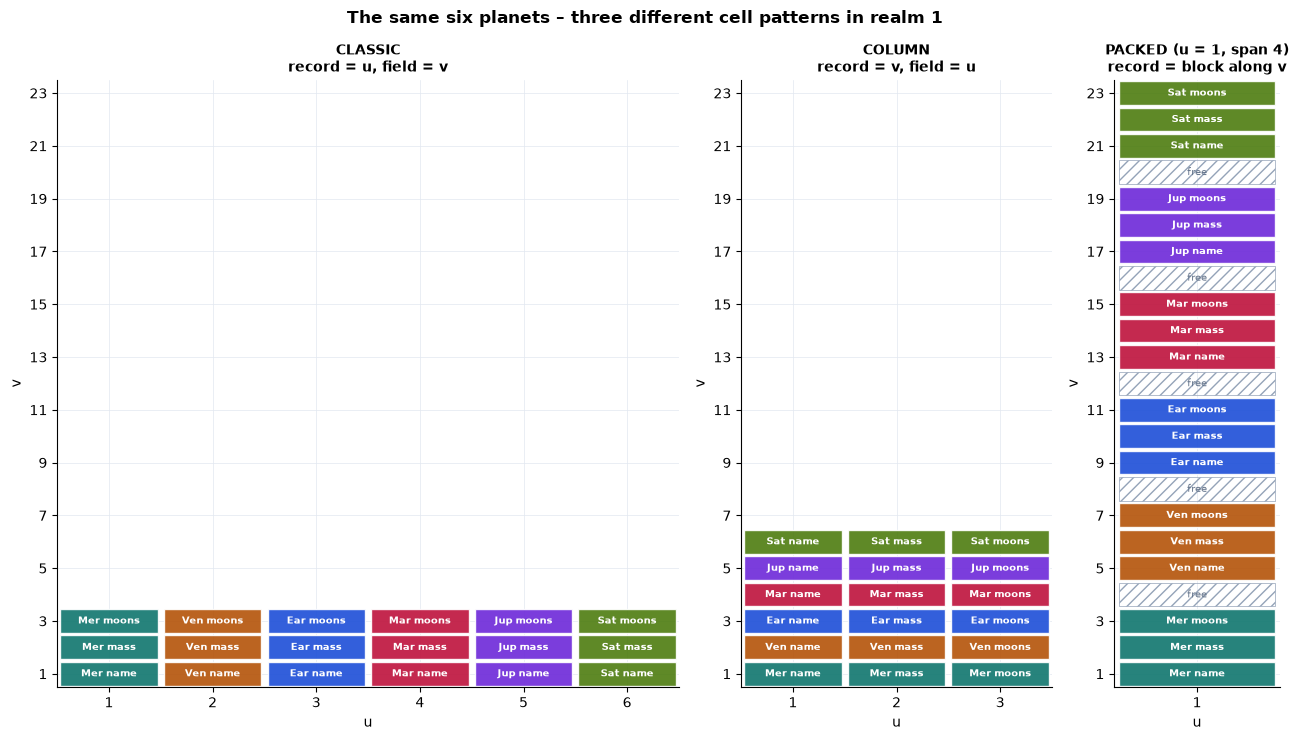

In [3]:
u_max = {k: max(c["u"] for c in cs) for k, cs in cells.items()}
v_top = max(c["v"] for cs in cells.values() for c in cs)
fig, axes = plt.subplots(1, 3, figsize=(13, 7.5),
                         gridspec_kw={"width_ratios": [u_max["CLASSIC"], u_max["COLUMN"], max(1.6, u_max["PACKED"])]})
descr = {"CLASSIC": "CLASSIC\nrecord = u, field = v", "COLUMN": "COLUMN\nrecord = v, field = u",
         "PACKED": f"PACKED (u = 1, span {SPAN})\nrecord = block along v"}
for ax, kind in zip(axes, ("CLASSIC", "COLUMN", "PACKED")):
    plot_layout_cells(ax, cells[kind], u_max[kind], v_top, descr[kind])
for v in range(1, v_top + 1):                       # free offsets inside the PACKED blocks
    if (v - 1) % SPAN >= len(FIELDS):
        axes[2].add_patch(Rectangle((1 - 0.47, v - 0.45), 0.94, 0.9, fill=False, hatch="///",
                                    edgecolor="#94a3b8", lw=0.5))
        axes[2].text(1, v, "free", ha="center", va="center", fontsize=7, color="#64748b")
fig.suptitle("The same six planets – three different cell patterns in realm 1",
             fontweight="bold")
plt.tight_layout()
plt.show()

**What happened?** One dataset, three shapes on the address plane:

* **CLASSIC** – each planet is a column `u`, its three fields stacked at `v = 1, 2, 3`.
* **COLUMN** – each *field* is a column `u`; the planets run along `v`. All masses share `u = 2`:
  ideal when you mostly read one field of many records.
* **PACKED** – everything lives on a single `u`; each planet is a block of `span` cells along `v`.
  The fourth cell of each block (offset 3) is free – room for a field you may add later.

The table below shows the actual addresses and numbers for one planet. **Ah – the layout is a
choice, the address space is fixed.**

In [4]:
rows = []
for f, _ in FIELDS:
    row = {"field of Earth": f}
    for kind in ("CLASSIC", "COLUMN", "PACKED"):
        c = next(c for c in cells[kind] if c["object"] == 3 and c["field"] == f)
        row[kind] = f"(u={c['u']}, v={c['v']})  N={c['N']}"
    rows.append(row)
pd.DataFrame(rows).set_index("field of Earth")

,CLASSIC,COLUMN,PACKED
field of Earth,,,
name,"(u=3, v=1) N=13","(u=1, v=3) N=15","(u=1, v=9) N=99"
mass,"(u=3, v=2) N=22","(u=2, v=3) N=23","(u=1, v=10) N=120"
moons,"(u=3, v=3) N=33","(u=3, v=3) N=33","(u=1, v=11) N=143"


In [5]:
# Reading by number works in every layout – the engine knows which layout owns the cell.
for kind, path in paths.items():
    with nhydb.open(path) as db:
        n = next(c["N"] for c in cells[kind] if c["object"] == 3 and c["field"] == "moons")
        hit = db.get_n(n, mode="cell")
        print(f"{kind:8} N = {n:3} → layout {hit['layout_kind']}, object {hit['object']}, "
              f"field {hit['field']!r} = {hit['value']}")
        assert hit["object"] == 3 and hit["value"] == 1

CLASSIC  N =  33 → layout CLASSIC, object 3, field 'moons' = 1
COLUMN   N =  33 → layout COLUMN, object 3, field 'moons' = 1
PACKED   N = 143 → layout PACKED, object 3, field 'moons' = 1


## 2 · Several layouts in one realm: routing

**Question:** Layouts can share a realm with different `u` ranges. Who owns a given `u`?

**The winner rule:** among all layouts whose `u` range contains `u`

1. the higher **priority** wins,
2. then the **narrower** range,
3. then the higher layout **id**.

▶ **Run it:** a catch-all layout for `u ≥ 1`, an *archive* for `u = 1000 … 1999` (narrower) and a
*vip* range `u = 1500 … 1599` with priority 5.

In [6]:
PATH_R = db_path("routing.nhydb")
with nhydb.create(PATH_R) as db:
    db.create_realm(1, "mixed")
    db.create_shape(1, 1, "s", [{"v": 1, "name": "x", "type": "u32"}])
    db.create_classic_layout(1, 1, "all", shape_id=1)                                        # u = 1 … ∞
    db.create_layout(2, 1, "archive", "CLASSIC", shape_id=1, u_start=1000, u_end=1999)       # narrower
    db.create_layout(3, 1, "vip", "CLASSIC", shape_id=1, u_start=1500, u_end=1599, priority=5)
    db.commit()

    probe = [1, 999, 1000, 1499, 1500, 1599, 1600, 1999, 2000]
    routing = pd.DataFrame([{"u": u, "winner": db.layout_at(1, u).name,
                             "candidates": [l.name for l in db.layout_candidates(1, u)]} for u in probe])
    diag = db.layout_diagnostics(1)
    us = list(range(1, 2501, 5))
    winners = [db.layout_at(1, u).name for u in us]
    route = db.route_address(1, 1550, 1)
print("diagnostics:", diag["summary"])
print("route_address(1, 1550, 1):", route["layout_name"], "– candidates:", [c["name"] for c in route["candidates"]])
assert route["layout_name"] == "vip"
routing.set_index("u")

diagnostics: {'realms': 1, 'overlaps': 3, 'conflicts': 0, 'gaps': 0}
route_address(1, 1550, 1): vip – candidates: ['vip', 'archive', 'all']


,winner,candidates
u,,
1,all,[all]
999,all,[all]
1000,archive,"[archive, all]"
1499,archive,"[archive, all]"
1500,vip,"[vip, archive, all]"
1599,vip,"[vip, archive, all]"
1600,archive,"[archive, all]"
1999,archive,"[archive, all]"
2000,all,[all]


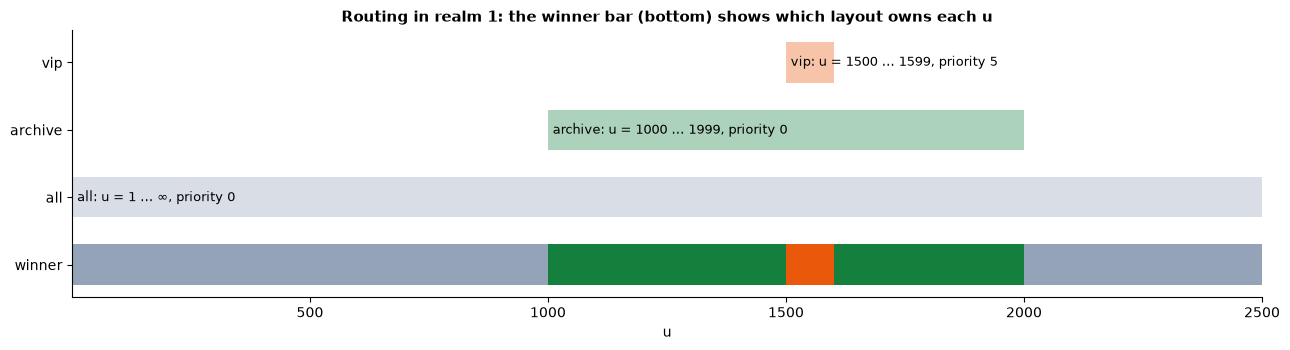

In [7]:
ranges = [("all", 1, 2500, 0), ("archive", 1000, 1999, 0), ("vip", 1500, 1599, 5)]
layer_colors = {"all": "#94a3b8", "archive": COLORS["B"], "vip": COLORS["attention"]}
fig, ax = plt.subplots(figsize=(13, 3.6))
for i, (name, a, b, prio) in enumerate(ranges):
    ax.barh(i + 1, b - a + 1, left=a, height=0.6, color=layer_colors[name], alpha=0.35)
    ax.text(a + 10, i + 1, f"{name}: u = {a} … {'∞' if name == 'all' else b}, priority {prio}",
            va="center", fontsize=9)
for u, w in zip(us, winners):
    ax.barh(0, 5, left=u, height=0.6, color=layer_colors[w])
ax.set_yticks([0, 1, 2, 3])
ax.set_yticklabels(["winner", "all", "archive", "vip"])
ax.set_xlabel("u")
ax.set_xlim(1, 2500)
ax.set_title("Routing in realm 1: the winner bar (bottom) shows which layout owns each u")
plt.tight_layout()
plt.show()

**What happened?** For `u < 1000` only *all* matches. From 1000 the *archive* wins because its range
is narrower. Between 1500 and 1599 the *vip* layout wins by priority. `layout_diagnostics` reports
the overlaps and confirms there is no conflict.

## 3 · Changing a layout safely

**Question:** Can layouts change after data has been written?

Yes – as long as **no stored data would get a different owner**. `plan_layout_evolution` is a dry
run that shows exactly which `u` ranges would be re-routed and whether stored data is affected;
`evolve_layout` applies only safe changes.

In [8]:
PATH_E = db_path("evolution.nhydb")
with nhydb.create(PATH_E) as db:
    db.create_realm(1, "r")
    db.create_shape(1, 1, "s", [{"v": 1, "name": "x", "type": "u32"}])
    db.create_classic_layout(1, 1, "all", shape_id=1)
    db.put(1, 150, [7], commit=True)                                 # stored by 'all' at u = 150

    # (a) a new layout over occupied space is rejected
    try:
        db.create_layout(2, 1, "vip", "CLASSIC", shape_id=1, u_start=100, u_end=199, priority=5)
    except nhydb.SchemaError as e:
        print("(a) create over u = 150 →", str(e).split(". Check")[0])

    # (b) a new layout over empty space is fine
    db.create_layout(3, 1, "vip", "CLASSIC", shape_id=1, u_start=300, u_end=399, priority=5)
    db.put(1, 250, [8], commit=True)                                 # stored by 'all' at u = 250

    # (c) dry run: extend vip to the left
    for start in (200, 260):
        plan = db.plan_layout_evolution(3, u_start=start)
        print(f"(c) plan u_start = {start}: status {plan['status']!r}, "
              f"re-routed {[(r['from'], r['to']) for r in plan['routing_changes']]}, "
              f"stored data at risk: {plan['occupied_impact']['sample_u']}")

    # (d) apply: the unsafe change is rejected, the safe one is applied
    try:
        db.evolve_layout(3, u_start=200)
    except nhydb.SchemaError as e:
        print("(d) evolve to 200 →", str(e)[:70], "…")
    print("(d) evolve to 260 →", db.evolve_layout(3, u_start=260, commit=True))
    assert db.layout_at(1, 250).name == "all" and db.layout_at(1, 260).name == "vip"
    assert db.get(1, 250)["x"] == 8

(a) create over u = 150 → layout change would re-route already materialized space (dense<=1, sparse_cells=0, sample_u=[150])
(c) plan u_start = 200: status 'unsafe', re-routed [(200, 299)], stored data at risk: [250]
(c) plan u_start = 260: status 'safe', re-routed [(260, 299)], stored data at risk: []
(d) evolve to 200 → UNSAFE layout evolution: already materialized space would be re-routed …
(d) evolve to 260 → LayoutDef(layout_id=3, realm_id=1, name="vip", kind='CLASSIC', u_start=260, u_end=399, priority=5)


**What happened?** Moving *vip* down to `u = 200` would take the stored record at `u = 250` away
from *all* – the dry run marks it **unsafe** and `evolve_layout` refuses. Stopping at `u = 260`
only re-routes empty space and is applied. **Ah – the schema may evolve, but stored data never
silently changes its owner.**

## 4 · Your turn

**Task:** add a fourth database with PACKED `span = 3` (no free offset). Which `v` does the anchor of
planet 5 have? Predict first: `anchor = (object − 1) · span + 1`.

In [9]:
p = db_path("planets_packed3.nhydb")
with nhydb.create(p) as db:
    db.create_realm(1, "planets")
    db.create_packed_layout(1, 1, "planets", u=1, span=3,
                            fields=[{"offset": i, "name": n, "type": t} for i, (n, t) in enumerate(FIELDS)])
    db.put_objects_batch(1, list(PLANETS.items()), commit=True)
    anchor = db.record_anchor(1, 5)
print(f"planet 5 starts at u = {anchor['u']}, v = {anchor['v_local']}  (prediction: {(5 - 1) * 3 + 1})")
assert anchor["v_local"] == (5 - 1) * 3 + 1

planet 5 starts at u = 1, v = 13  (prediction: 13)


## ⏩ Advanced: a CUSTOM layout – one planet per Dynadron group

A CUSTOM layout delegates the mapping to a Python object. Only the plugin **name** is stored in the
schema; the object must be registered again after every open. It needs
`logical_address(layout, object_id, field, lane)`, `type_of(layout, address)` and
`describe(layout, address)`.

Our plugin puts the three fields of object `k` on the **diagonal** `u + v = k + 3` – one whole
group `G` per planet:

```text
name  → (u = k + 2, v = 1)      mass → (u = k + 1, v = 2)      moons → (u = k, v = 3)
```

On lane NL, `N = G² − u`, so the three cells of a planet get **three consecutive numbers**.

In [10]:
FIELD_NAMES = [f for f, _ in FIELDS]
FIELD_TYPES = dict(FIELDS)


class OnePlanetPerGroup:
    def logical_address(self, layout, object_id, field, lane):
        j = 0 if field is None else FIELD_NAMES.index(field)          # field=None → anchor
        return {"u": object_id + 2 - j, "v": 1 + j, "lane": lane}

    def type_of(self, layout, address):
        return FIELD_TYPES[FIELD_NAMES[address["v"] - 1]]

    def describe(self, layout, address):
        j = address["v_local"] - 1
        return {"record": address["u"] + address["v_local"] - 3, "field": FIELD_NAMES[j], "anchor": j == 0}


PATH_C = db_path("planets_custom.nhydb")
with nhydb.create(PATH_C) as db:
    db.create_realm(1, "planets")
    db.create_custom_layout(1, 1, "groups", plugin="one-planet-per-group", u_start=1, u_end=None,
                            params={"fields": [{"name": f} for f in FIELD_NAMES]})
    db.register_layout_plugin("one-planet-per-group", OnePlanetPerGroup())
    db.put_objects_batch(1, list(PLANETS.items()), commit=True)
    custom = []
    for k, rec in PLANETS.items():
        ns = [db.logical_address(1, k, f)["N"] for f in FIELD_NAMES]
        custom.append({"planet": rec["name"], "group G": k + 3, "N of name, mass, moons": ns})
        assert ns == list(range(ns[0], ns[0] + 3))                      # consecutive numbers
    assert db.get_n(custom[2]["N of name, mass, moons"][0])["data"]["name"] == "Earth"

with nhydb.open(PATH_C) as db:                                          # plugin not registered yet
    try:
        db.get_object(1, 3)
    except nhydb.SchemaError as e:
        print("after reopen without plugin →", e)
pd.DataFrame(custom).set_index("planet")

after reopen without plugin → CUSTOM layout requires registered plugin 'one-planet-per-group'


,group G,"N of name, mass, moons"
planet,,
Mercury,4,"[13, 14, 15]"
Venus,5,"[21, 22, 23]"
Earth,6,"[31, 32, 33]"
Mars,7,"[43, 44, 45]"
Jupiter,8,"[57, 58, 59]"
Saturn,9,"[73, 74, 75]"


Each planet now occupies one complete diagonal of the address plane, and its fields are neighbours on
the number line. CUSTOM layouts let you design any geometry – the engine still checks types, lanes
and ownership, and `N` still names every cell.

## Summary

* CLASSIC, COLUMN and PACKED place the same records on different cells; reading gives identical objects.
* `logical_address` shows the real `(u, v)` and `N` of every field; `get_n` works in every layout.
* Several layouts can share a realm; priority, then the narrower range, then the id decide the owner.
* `plan_layout_evolution` is a dry run; changes that would re-route stored data are rejected.
* CUSTOM plugins implement any geometry in Python – e.g. one record per Dynadron group.

## Where to go next

* [05 · MATH_MAP](05_math_map_text_and_formula_lab_v1.ipynb) – a formula as the layout.
* [09 · Asking Questions of the Data](09_queries_and_sql_v1.ipynb) – queries across layouts.

**Cookbook sections:** 17 (Layouts: COLUMN, PACKED, CUSTOM, routing and evolution) in the [NHyDB Python Cookbook](https://github.com/nhydb/NHyDB/blob/main/docs/cookbook/PYTHON_COOKBOOK.md).

In [11]:
# Clean up: remove the temporary folder with all databases of this notebook.
cleanup()
print("Temporary files removed.")

Temporary files removed.
